<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/04_evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, sys, time
import torch

Mounted at /content/drive


In [3]:
project_dir= Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir= project_dir/"artifacts"
src_dir= project_dir/"src"            # reusable .py files live here
data_dir= Path("/content/data")

artifacts_dir.mkdir(parents=True, exist_ok=True)
src_dir.mkdir(parents=True, exist_ok= True)
data_dir.mkdir(parents=True, exist_ok= True)

In [4]:
seed= 42
torch.manual_seed(seed)

# Select GPU when CUDA is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [5]:
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C /content/data
!ls /content/data/oxford-iiit-pet

/content/pets.tgz   100%[===================>] 774.10M  41.8MB/s    in 19s     
annotations  images


In [12]:
# Load the previously saved training and validation indices
with open(artifacts_dir/"splits.json") as f:
    splits= json.load(f)

train_idx= splits["train"]
val_idx= splits["val"]

# Load the numerical index-to-breed mapping
with open(artifacts_dir/"classes.json") as f:
    idx_to_class= json.load(f)

print("train:", len(train_idx), "val:", len(val_idx))   # 3128, 552
print("class 0:", idx_to_class["0"])

train: 3128 val: 552
class 0: Abyssinian


In [13]:
# Which architecture model.pt is (saved on Day 3)
with open(artifacts_dir/"model_config.json") as f:
    config = json.load(f)

# breed -> "cat"/"dog" (saved on Day 1)
with open(artifacts_dir/"breed_species.json") as f:
    breed_species = json.load(f)

# A plain list: position i = breed name (JSON keys are strings, so str(i))
classes = [idx_to_class[str(i)] for i in range(37)]

print(config)
print(classes[:3])

{'name': 'resnet50', 'num_classes': 37, 'val_acc': 0.9510869565217391}
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier']



### Loading Model Metadata and Preparing Class Labels

Loaded the model configuration and breed-to-species mapping from previously saved JSON artifacts. Created an ordered list of breed names using `idx_to_class`, ensuring that each list position corresponds to the correct model output index. This mapping will be used to interpret the model's predictions.


In [14]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(project_dir))
import src.data, src.model
importlib.reload(src.data)
importlib.reload(src.model)
from src.data import get_eval_transform
from src.model import build_model

from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader

# Load the test dataset with the evaluation transformations
test_ds= OxfordIIITPet(
    root= data_dir,
    split= "test",
    target_types= "category",
    transform= get_eval_transform()
)

# Create a DataLoader without shuffling to preserve dataset order
test_loader= DataLoader(
    test_ds,
    batch_size= 64,
    shuffle= False,
    num_workers= 2
)

# Extract filenames in the same order as the test dataset
test_files= [Path(p).name for p in test_ds.images]

print("Test images:", len(test_ds))


test images: 3669



### Loading the Test Dataset

Reloaded the project modules to incorporate the latest code changes and initialized the Oxford-IIIT Pet test dataset using the evaluation transformations. Created a DataLoader with a batch size of 64 and disabled shuffling to preserve the original dataset order. Extracted the corresponding image filenames so that predictions can later be matched with their respective images.


In [15]:
# Final fine-tuned model (architecture name comes from model_config.json)
final_model= build_model(
    config["name"], num_classes=37, freeze=False
    ).to(device)

final_model.load_state_dict(
    torch.load(artifacts_dir/"model.pt", map_location=device)
    )

# Day 2 frozen baseline
baseline_model= build_model(
    "efficientnet_b0", num_classes=37, freeze=True
    ).to(device)

baseline_model.load_state_dict(
    torch.load(artifacts_dir/"baseline_b0.pt", map_location=device)
    )

print("Loaded final:", config["name"], "+ baseline")

Loaded final: resnet50 + baseline


In [16]:
def predict_all(model, loader, device):
    """Generate class probabilities and true labels in dataset order."""
    model.eval()

    all_probs, all_labels = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(images)                  # Raw scores for 37 breeds
            probs = torch.softmax(logits, dim=1)    # Convert scores to probabilities

            all_probs.append(probs.cpu())
            all_labels.append(labels)

    return torch.cat(all_probs), torch.cat(all_labels)


# Generate predictions using both models
final_probs, y_true = predict_all(final_model, test_loader, device)
baseline_probs, _ = predict_all(baseline_model, test_loader, device)

# Extract predicted class, confidence and top-5 predictions
conf, y_pred = final_probs.max(dim=1)
top5_idx = final_probs.topk(5, dim=1).indices
baseline_pred = baseline_probs.argmax(dim=1)

# Convert tensors to NumPy for evaluation and visualization
y_true = y_true.numpy()
y_pred = y_pred.numpy()
conf = conf.numpy()
top5_idx = top5_idx.numpy()
baseline_pred = baseline_pred.numpy()

# Verify prediction dimensions and ground-truth labels
unique_labels = np.unique(y_true)

print("Prediction shape:", final_probs.shape)
print("Number of ground-truth classes:", len(unique_labels))
print("Ground-truth probability sum:", final_probs[0].sum().item())

Prediction shape: torch.Size([3669, 37])
Number of ground-truth classes: 37
Ground-truth probability sum: 1.0



### Generating Predictions from Both Models

This cell performs inference on the test dataset using the final model and baseline model, collecting predictions for all 3,669 images.

**1. Defining the Prediction Function**

The `predict_all()` function accepts a trained model, DataLoader and computation device.

- `model.eval()` switches the model to evaluation mode.
- `torch.no_grad()` disables gradient tracking since we are only performing inference and not updating model weights.
- Images are moved to the specified device before being passed through the model.
- The model generates logits (raw class scores), which are converted into probabilities using `torch.softmax(logits, dim=1)`.
- Probabilities and corresponding ground-truth labels are collected batch by batch.
- `torch.cat()` combines all batches into complete tensors.

**2. Generating Predictions**

The function is called separately for the final model and baseline model using the same test dataset.

- `final_probs` stores the final model's probabilities.
- `baseline_probs` stores the baseline model's probabilities.
- `y_true` stores the actual breed labels. The labels returned by the second call are ignored because they are identical.

**3. Extracting Prediction Information**

From the final model's probabilities:

- `max(dim=1)` extracts the highest probability and its corresponding predicted class index for each image.
- `topk(5, dim=1).indices` retrieves the five most likely breed class indices for each image.
- `argmax(dim=1)` extracts the baseline model's highest-probability class index.

The confidence score represents the model's highest predicted probability for an image.

**4. Converting Tensors to NumPy**

The collected predictions are converted from PyTorch tensors to NumPy arrays using `.numpy()`. This makes them convenient to use with Pandas, scikit-learn and visualization libraries for further evaluation.

**5. Verification**

Finally, we check:
- Prediction shape: `(3669, 37)`, representing 3,669 images and 37 breed classes.
- Number of unique ground-truth classes: verifies that all 37 breed classes are represented.
- Probability sum: verifies that the probabilities for an individual image add up to approximately 1.

**Outcome:** We now have the final model's predictions, baseline model's predictions, actual breed labels, confidence scores and top-5 predictions ready for evaluation and comparison.


In [17]:
rows = []
for i in range(len(test_files)):
    true_breed = classes[y_true[i]]
    pred_breed = classes[y_pred[i]]
    top5_names = [classes[j] for j in top5_idx[i]]

    rows.append({
        "filename": test_files[i],
        "true_breed": true_breed,
        "pred_breed": pred_breed,
        "species": breed_species[true_breed],
        "confidence": round(float(conf[i]), 4),
        "correct": true_breed == pred_breed,
        "in_top5": true_breed in top5_names,
        "top5": "|".join(top5_names),          # one text column, e.g. "Beagle|Basset Hound|..."
    })

pred_df = pd.DataFrame(rows)
pred_df.to_csv(artifacts_dir / "predictions.csv", index=False)
pred_df.head()

,filename,true_breed,pred_breed,species,confidence,correct,in_top5,top5
0,Abyssinian_201.jpg,Abyssinian,Abyssinian,cat,0.7283,True,True,Abyssinian|Bengal|Chihuahua|Miniature Pinscher...
1,Abyssinian_202.jpg,Abyssinian,Abyssinian,cat,0.8225,True,True,Abyssinian|Bengal|American Pit Bull Terrier|Mi...
2,Abyssinian_204.jpg,Abyssinian,Bengal,cat,0.5207,False,True,Bengal|Abyssinian|Miniature Pinscher|Siamese|A...
3,Abyssinian_205.jpg,Abyssinian,Bengal,cat,0.5910,False,True,Bengal|Abyssinian|Maine Coon|Yorkshire Terrier...
4,Abyssinian_206.jpg,Abyssinian,Bengal,cat,0.8905,False,True,Bengal|Abyssinian|Siamese|Sphynx|Bombay



### Creating a Prediction DataFrame

Converted the model's predictions into a structured Pandas DataFrame containing one record per test image.

- **Breed mapping:** Converted numerical class indices into their corresponding breed names using the `classes` list.
- **Species identification:** Used the `breed_species` mapping to identify whether the actual breed belongs to a cat or dog.
- **Confidence:** Stored the highest predicted probability, rounded to four decimal places.
- **Correctness:** Created a Boolean column indicating whether the predicted breed matches the actual breed.
- **Top-5 accuracy:** Recorded whether the actual breed appears among the model's five highest-probability predictions.
- **Top-5 predictions:** Combined the five predicted breed names into a single string separated by `|`.

Finally, converted the collected records into a Pandas DataFrame, saved it as `predictions.csv` in the artifacts directory and displayed the first five rows for inspection.


In [19]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate overall classification performance
test_acc = accuracy_score(y_true, y_pred)
top5_acc = pred_df["in_top5"].mean()
macro_f1 = f1_score(y_true, y_pred, average="macro")

# Calculate accuracy separately for cats and dogs
cat_acc = pred_df[pred_df["species"] == "cat"]["correct"].mean()
dog_acc = pred_df[pred_df["species"] == "dog"]["correct"].mean()

# Evaluate baseline model on the same test dataset
baseline_test_acc = accuracy_score(y_true, baseline_pred)

# Collect evaluation metrics for saving
metrics = {
    "model": config["name"],
    "n_test": int(len(y_true)),
    "test_acc": round(float(test_acc), 4),
    "top5_acc": round(float(top5_acc), 4),
    "macro_f1": round(float(macro_f1), 4),
    "cat_acc": round(float(cat_acc), 4),
    "dog_acc": round(float(dog_acc), 4),
    "baseline_test_acc": round(float(baseline_test_acc), 4),
}

# Save metrics as a JSON artifact
with open(artifacts_dir / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Display all evaluation metrics
for k, v in metrics.items():
    print(f"{k}: {v}")


model: resnet50
n_test: 3669
test_acc: 0.9245
top5_acc: 0.9913
macro_f1: 0.9239
cat_acc: 0.8791
dog_acc: 0.9461
baseline_test_acc: 0.8471



### Evaluating Model Performance

Evaluated the final model using multiple classification metrics and compared its performance against the baseline model.

- **Test Accuracy:** Measures the proportion of correctly classified images across all 37 breeds.
- **Top-5 Accuracy:** Measures how often the actual breed appears among the model's five highest-probability predictions.
- **Macro F1 Score:** Calculates the F1 score independently for each breed and takes their unweighted average, giving equal importance to all classes.
- **Cat Accuracy:** Measures classification accuracy across images belonging to cat breeds.
- **Dog Accuracy:** Measures classification accuracy across images belonging to dog breeds.
- **Baseline Accuracy:** Measures the baseline model's accuracy on the same test dataset for comparison.

All metrics are collected in a dictionary, rounded to four decimal places and converted into standard Python data types for JSON compatibility.

Finally, the evaluation results are saved to `metrics.json` in the artifacts directory and printed for inspection.


In [20]:
# Calculate F1 score separately for each breed
per_class_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    labels=list(range(len(classes)))
)

rows = []

# Calculate evaluation metrics for each breed
for i, breed in enumerate(classes):
    breed_rows = pred_df[pred_df["true_breed"] == breed]

    rows.append({
        "breed": breed,
        "species": breed_species[breed],
        "n_test": len(breed_rows),
        "accuracy": round(float(breed_rows["correct"].mean()), 4),
        "f1": round(float(per_class_f1[i]), 4),
    })

# Create a DataFrame and sort breeds by accuracy (lowest first)
per_class = pd.DataFrame(rows).sort_values("accuracy")

# Save per-breed evaluation results
per_class.to_csv(artifacts_dir / "per_class.csv", index=False)

# Display the 10 hardest breeds to classify
per_class.head(10)


,breed,species,n_test,accuracy,f1
2,American Pit Bull Terrier,dog,100,0.5500,0.6667
34,Staffordshire Bull Terrier,dog,89,0.7528,0.7016
26,Ragdoll,cat,100,0.7900,0.7783
9,British Shorthair,cat,100,0.8200,0.8865
11,Egyptian Mau,cat,97,0.8247,0.8791
20,Maine Coon,cat,100,0.8300,0.8877
6,Birman,cat,100,0.8300,0.8098
27,Russian Blue,cat,100,0.8700,0.9110
32,Siamese,cat,100,0.8800,0.9119
0,Abyssinian,cat,98,0.9082,0.9271



### Per-Breed Performance Evaluation

Evaluated the model's performance separately across all 37 breed classes to identify which breeds are classified accurately and which are more challenging.

- **Per-Class F1 Score:** Used `average=None` to calculate an individual F1 score for each breed instead of combining them into a single macro average. Class labels ensure the scores follow the same order as the `classes` list.
- **Breed-wise Evaluation:** Iterated through all breeds and calculated:
  - `species`: Whether the breed belongs to a cat or dog.
  - `n_test`: Number of test images belonging to that breed.
  - `accuracy`: Proportion of correctly classified images for that breed.
  - `f1`: Individual F1 score for that breed.
- **Sorting:** Sorted the results by accuracy in ascending order to bring the most challenging breeds to the top.

Finally, saved the complete per-breed evaluation results to `per_class.csv` and displayed the 10 breeds with the lowest classification accuracy.

**Observation:** American Pit Bull Terrier has the lowest accuracy (55%), followed by Staffordshire Bull Terrier (75.28%). This helps identify specific breeds where the classifier may need improvement.


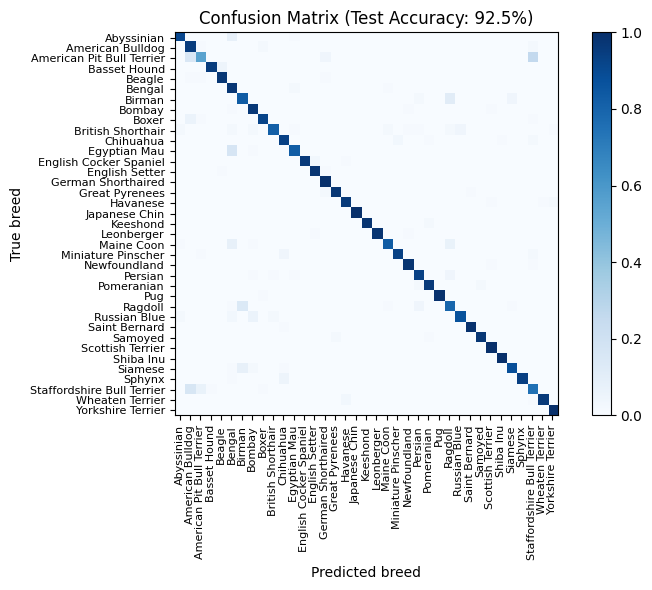

In [23]:
from sklearn.metrics import confusion_matrix

# Calculate row-normalized confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    normalize="true"
)

# Create and configure the heatmap
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)

# Set breed names as axis labels
ax.set_xticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90, fontsize=8)
ax.set_yticks(range(len(classes)))
ax.set_yticklabels(classes, fontsize=8)

ax.set_xlabel("Predicted breed")
ax.set_ylabel("True breed")
ax.set_title(f"Confusion Matrix (Test Accuracy: {test_acc:.1%})")

# Add color scale
fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()

# Save and display the confusion matrix
plt.savefig(artifacts_dir / "confusion.png", dpi=120)
plt.show()



### Visualizing the Confusion Matrix

Generated a row-normalized confusion matrix to examine how effectively the model distinguishes between the 37 pet breeds.

- **Rows:** Represent the actual breed labels.
- **Columns:** Represent the model's predicted breed labels.
- **Diagonal cells:** Represent correctly classified images.
- **Off-diagonal cells:** Show misclassifications, helping identify which breeds the model confuses with others.
- **Color intensity:** Darker blue indicates a higher proportion of predictions for that class.

The matrix was normalized using `normalize="true"`, allowing classification performance to be compared across breeds independently of their test sample counts.

The heatmap was generated using Matplotlib, with breed names displayed on both axes and a color bar indicating prediction proportions.

Finally, the confusion matrix was saved as `confusion.png` in the artifacts directory.


**Observation:** The confusion matrix shows a strong diagonal pattern, indicating that the model correctly classifies most breeds. However, noticeable confusion exists between American Pit Bull Terrier and American Bulldog, suggesting that the model sometimes struggles to distinguish between these visually similar breeds. The overall test accuracy is 92.5%.



In [24]:
cm_counts = confusion_matrix(y_true, y_pred, labels=list(range(37)))

pairs = []
for i in range(37):
    for j in range(37):
        if i != j and cm_counts[i, j] > 0:          # off-diagonal = a mistake
            pairs.append({"true": classes[i],
                          "predicted": classes[j],
                          "count": int(cm_counts[i, j])})

pairs_df = pd.DataFrame(pairs).sort_values("count", ascending=False).head(10)
pairs_df.to_csv(artifacts_dir / "confused_pairs.csv", index=False)
pairs_df

,true,predicted,count
7,American Pit Bull Terrier,Staffordshire Bull Terrier,26
37,Egyptian Mau,Bengal,16
5,American Pit Bull Terrier,American Bulldog,15
68,Ragdoll,Birman,14
85,Staffordshire Bull Terrier,American Bulldog,14
15,Birman,Ragdoll,11
0,Abyssinian,Bengal,8
52,Maine Coon,Bengal,8
80,Siamese,Birman,8
54,Maine Coon,Ragdoll,7



### Identifying the Most Confused Breed Pairs

Analysed the unnormalized confusion matrix to identify the most frequent breed misclassifications.

- Generated a confusion matrix using actual and predicted breed labels without normalization, preserving the raw misclassification counts.
- Iterated through all 37 × 37 class combinations and extracted off-diagonal entries, representing incorrect predictions.
- Stored each misclassification as a pair containing the actual breed, predicted breed and number of occurrences.
- Sorted the pairs by misclassification count in descending order to identify the most frequently confused breeds.
- Saved the top 10 confused pairs to `confused_pairs.csv`.

**Observation:** American Pit Bull Terrier is frequently confused with Staffordshire Bull Terrier (26 images) and American Bulldog (15 images). Other notable confusions include Egyptian Mau with Bengal (16 images) and Ragdoll with Birman (14 images). These results highlight breeds with similar visual characteristics that may be challenging for the classifier to distinguish.


In [25]:
from PIL import Image

# Create a directory to store misclassified images
errors_dir = artifacts_dir / "errors"
errors_dir.mkdir(exist_ok=True)

# Path to the original dataset images
images_dir = data_dir / "oxford-iiit-pet" / "images"

saved = 0

# Iterate through the most frequently confused breed pairs
for _, pair in pairs_df.iterrows():

    # Select up to 4 images for each actual-predicted breed combination
    mistakes = pred_df[
        (pred_df["true_breed"] == pair["true"]) &
        (pred_df["pred_breed"] == pair["predicted"])
    ].head(4)

    for k, (_, row) in enumerate(mistakes.iterrows()):

        # Open the misclassified image and convert it to RGB
        img = Image.open(images_dir / row["filename"]).convert("RGB")

        # Resize while preserving the original aspect ratio
        img.thumbnail((400, 400))

        # Create a descriptive filename using the breed pair and image index
        name = f'{pair["true"]}__{pair["predicted"]}__{k}.jpg'.replace(" ", "_")

        # Save the image with JPEG quality of 85
        img.save(errors_dir / name, quality=85)
        saved += 1

print("Saved", saved, "error images")


Saved 40 error images



### Saving Misclassified Images for Visual Inspection

Extracted actual test images corresponding to the most frequently confused breed pairs identified in the previous analysis.

- Created an `errors` directory inside the artifacts folder to store misclassified images.
- Iterated through the top 10 confused breed pairs and selected up to four images for each actual-predicted breed combination.
- Used Pillow (`PIL`) to open the original images and convert them to RGB format.
- Resized images to fit within 400 × 400 pixels while preserving their aspect ratios.
- Saved each image with a descriptive filename containing its actual breed, predicted breed and image index.
- Used JPEG quality 85 to reduce storage requirements while retaining reasonable image quality.

Finally, printed the total number of saved error images.

**Purpose:** These images will help visually investigate why the classifier confuses certain breeds, potentially revealing similarities in facial features, coat patterns, body structure or other visual characteristics.


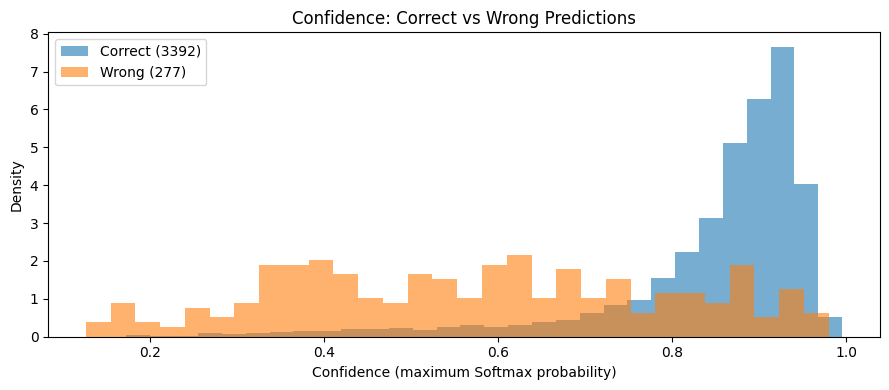

,threshold,wrong_caught_%,correct_rejected_%,acc_on_kept_%
0,0.3,9.4,0.6,93.1
1,0.4,26.7,1.8,94.3
2,0.5,39.0,3.8,95.1
3,0.6,53.8,6.2,96.1
4,0.7,69.7,10.1,97.3


In [26]:
# Separate confidence scores for correct and incorrect predictions
correct_conf = pred_df[pred_df["correct"]]["confidence"]
wrong_conf = pred_df[~pred_df["correct"]]["confidence"]

# Compare confidence distributions using overlapping histograms
plt.figure(figsize=(9, 4))

plt.hist(correct_conf, bins=30, alpha=0.6, density=True,
         label=f"Correct ({len(correct_conf)})")
plt.hist(wrong_conf, bins=30, alpha=0.6, density=True,
         label=f"Wrong ({len(wrong_conf)})")

plt.xlabel("Confidence (maximum Softmax probability)")
plt.ylabel("Density")
plt.title("Confidence: Correct vs Wrong Predictions")
plt.legend()
plt.tight_layout()

# Save and display the confidence distribution plot
plt.savefig(artifacts_dir / "confidence_hist.png", dpi=120)
plt.show()

# Evaluate the effect of different confidence thresholds
rows = []

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    rows.append({
        "threshold": t,
        "wrong_caught_%": round(100 * (wrong_conf < t).mean(), 1),
        "correct_rejected_%": round(100 * (correct_conf < t).mean(), 1),
        "acc_on_kept_%": round(
            100 * pred_df[pred_df["confidence"] >= t]["correct"].mean(), 1
        ),
    })

# Display threshold comparison results
pd.DataFrame(rows)



### Analysing Prediction Confidence and Thresholds

Investigated the relationship between model confidence and prediction correctness.

- Separated confidence scores into correctly and incorrectly classified predictions.
- Generated overlapping histograms to compare their confidence distributions. Density normalization was used to make the distributions comparable.
- Evaluated five confidence thresholds (0.3–0.7) to understand how different confidence requirements affect prediction reliability.

For each threshold, calculated:
- **Wrong Caught:** Percentage of incorrect predictions falling below the threshold.
- **Correct Rejected:** Percentage of correct predictions falling below the threshold.
- **Accuracy on Kept Predictions:** Accuracy among predictions meeting or exceeding the threshold.

Saved the confidence distribution plot as `confidence_hist.png`.

**Purpose:** To investigate whether low-confidence predictions are more likely to be incorrect and understand the trade-off between filtering uncertain predictions and retaining correct ones.


In [27]:
expected = ["model.pt", "model_config.json", "classes.json", "breed_species.json",
            "predictions.csv", "metrics.json", "per_class.csv", "confusion.png",
            "confused_pairs.csv", "confidence_hist.png"]

for name in expected:
    status = "Yes" if (artifacts_dir / name).exists() else " MISSING"
    print(status, name)

print("Yes" if len(list(errors_dir.glob("*.jpg"))) > 0 else "MISSING", "errors/",
      len(list(errors_dir.glob("*.jpg"))), "images")

Yes model.pt
Yes model_config.json
Yes classes.json
Yes breed_species.json
Yes predictions.csv
Yes metrics.json
Yes per_class.csv
Yes confusion.png
Yes confused_pairs.csv
Yes confidence_hist.png
Yes errors/ 40 images
